# 05. 성능 한계 진단 — 왜 score 가 0.45 근처에서 멈추는가

지금까지 E1~E6, T1~T6, M1~M4 에서 50개가 넘는 후보를 비교했지만, 단순 갭 규칙 **B2** (`label_of(k × 프리마켓 갭)`) 를
확실히 이긴 후보는 없었음. 이 노트북은 그 이유를 다섯 갈래로 나눠 그림으로 확인함.

| 절 | 질문 |
|---|---|
| 1 | 점수는 어떤 실수에서 깎이는가 (점수 구조) |
| 2 | 정보를 하나씩 "몰래" 알려 주면 점수는 어디까지 오르는가 (oracle 상한) |
| 3 | 프리마켓 갭은 당일 움직임을 얼마나 설명하는가 (방향·크기·되돌림) |
| 4 | 갭 말고 다른 feature 는 무엇을 알려 주는가 (방향 vs 크기) |
| 5 | 관측된 개선(+0.005)은 평가 잡음보다 큰가 (시간·종목·추첨 변동) |

**데이터 규칙**: DEV(대상일 < 2026-06-01)만 씀. lockbox 행은 `universe_panel` 이 자동으로 뺌.
oracle 실험은 정답을 일부 알려 주는 **상한 실험**이라 모델에는 쓰지 않음.

In [1]:
import sys, glob, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "eda"))
import eda_utils as U
from exp import config as C
from exp.panel import universe_panel
from exp.splits import partition, fold_masks
from exp.runner import _symbols
from src.data import WEIGHT, RET_CUTS, label_of
from src.model import fast_score

U.setup_plot()
pd.set_option("display.float_format", "{:.4f}".format)
CUTS = np.array(RET_CUTS)
LAB = ["급하락", "하락", "보합", "상승", "급상승"]

In [2]:
# -----------------------------------------------------------------------------
# 역할  : 5등급 label 로 바꿈 (과제 정의와 같음: 왼쪽 포함 구간 [−∞,−2.5) [−2.5,−0.6) [−0.6,0.6) [0.6,2.5) [2.5,∞))
# Input : s  등락률(%) 또는 신호 배열 (NaN → 보합 2)
# Output: int 배열 0~4
# -----------------------------------------------------------------------------
def to_label(s):
    s = np.asarray(s, float)
    return np.where(np.isnan(s), 2, np.searchsorted(CUTS, s, side="right"))


# -----------------------------------------------------------------------------
# 역할  : 신호 s 에 곱할 k 를 학습 행에서 score 최대로 고름 (B2 와 같은 방식)
# Input : s, y  학습 행의 신호·정답,  grid  k 후보
# Output: k (float)
# -----------------------------------------------------------------------------
def fit_k(s, y, grid=np.arange(0.5, 16.01, 0.25)):
    return float(max(grid, key=lambda k: fast_score(y, to_label(k * s))))


# -----------------------------------------------------------------------------
# 역할  : 혼동행렬 O, 기대행렬 E, 가중 손실 칸별 몫을 계산
# 수식  : E_ij = n_i · m_j / N,   loss_ij = w_ij · O_ij / Σ w·E,   score = 1 − Σ loss_ij
# Input : y, p  정답·예측 label
# Output: dict(O, E, loss, score, num = Σw·O / N, den = Σw·E / N)
# -----------------------------------------------------------------------------
def anatomy(y, p):
    O = np.zeros((5, 5)); np.add.at(O, (np.asarray(y, int), np.asarray(p, int)), 1)
    N = O.sum(); E = np.outer(O.sum(1), O.sum(0)) / N
    den = (WEIGHT * E).sum()
    return {"O": O, "E": E, "loss": WEIGHT * O / den, "score": 1 - (WEIGHT * O).sum() / den,
            "num": (WEIGHT * O).sum() / N, "den": den / N}


# -----------------------------------------------------------------------------
# 역할  : 시간 fold(A·B·C) 마다 학습 구간에서 k 를 고르고 평가 구간 점수를 냄 (oracle 사다리용)
# Input : df  패널,  signal  df → 신호 배열 함수,  fixed_k  k 를 고정하려면 값
# Output: 평가 행 전체를 모은 점수 (float), fold 별 k 목록
# -----------------------------------------------------------------------------
def fold_score(df, signal, fixed_k=None):
    ys, ps, ks = [], [], []
    for fd in C.DEFAULTS["split"]["folds"]:
        tr, te = fold_masks(df, df, fd, C.DEFAULTS["split"]["embargo_days"])
        s = signal(df)
        k = fixed_k if fixed_k is not None else fit_k(s[tr], df["label"].to_numpy()[tr])
        ys.append(df["label"].to_numpy()[te]); ps.append(to_label(k * s[te])); ks.append(k)
    return fast_score(np.concatenate(ys), np.concatenate(ps)), ks

In [3]:
# DEV 패널: 50종목을 20종목 universe 로 나눠 만든 feature 표 (lockbox 제외, 캐시 사용)
GROUPS = ["core", "scale", "cross", "event", "analyst", "har", "premkt", "txt_count", "txt_recent",
          "txt_tone_gdelt", "txt_body"]
unis = partition(_symbols(), 20, np.random.default_rng(C.derive_seed(20261011, "probe")))
panel = pd.concat([universe_panel(u, GROUPS) for u in unis], ignore_index=True)
panel = panel.dropna(subset=["gap_pct", "ret_pct"]).reset_index(drop=True)

# 09:30 시가 (상한 실험 전용, 모델에는 못 씀)
d = pd.read_parquet(ROOT / "dataset" / "daily.parquet", columns=["symbol", "date_et", "open"])
d["target"] = pd.to_datetime(d["date_et"]).dt.tz_localize(None).dt.normalize()
panel = panel.merge(d[["symbol", "target", "open"]], on=["symbol", "target"], how="left")
panel["open_gap"] = (panel["open"] / panel["close_d0"] - 1) * 100
panel["rest"] = panel["ret_pct"] - panel["gap_pct"]          # 08:00 이후 움직임 (09:30 cutoff 이후 대부분)

# 실험 결과 (M2: 같은 seed 로 3 추첨 × 3 fold 표본 밖 예측)
m2 = sorted(glob.glob(str(ROOT / "runs" / "m2_magnitude_*")))[-1]
pred = pd.read_parquet(Path(m2) / "predictions.parquet")
print(f"패널 {len(panel):,}행 ({panel.target.min().date()} ~ {panel.target.max().date()}),  표본 밖 예측 {len(pred):,}행")
print("label 분포:", panel["label"].value_counts(normalize=True).sort_index().round(3).to_dict())

패널 22,400행 (2024-08-14 ~ 2026-05-29),  표본 밖 예측 110,400행
label 분포: {0: 0.069, 1: 0.238, 2: 0.339, 3: 0.278, 4: 0.076}


## 1. 점수 구조 — 어떤 실수에서 점수가 깎이는가

### 1-1. 가중치 행렬 `w_ij = (i − j)² · (i − 2)²`

**heatmap** 은 표의 각 칸 값을 색의 진하기로 보여 주는 그림임. 행 = 정답 등급 i, 열 = 예측 등급 j.

이 가중치에는 두 가지 특징이 있음.
- `(i − j)²` : 멀리 틀릴수록 제곱으로 커짐
- `(i − 2)²` : **정답**이 보합에서 멀수록 커짐. 정답이 보합(i = 2)인 행은 **가중치가 전부 0** → 보합인 날에는 무엇을 예측해도 벌점이 없음.
  반대로 정답이 급등락(0·4)이면 가중치가 4배, 반대 극단으로 틀리면 16 × 4 = **64**

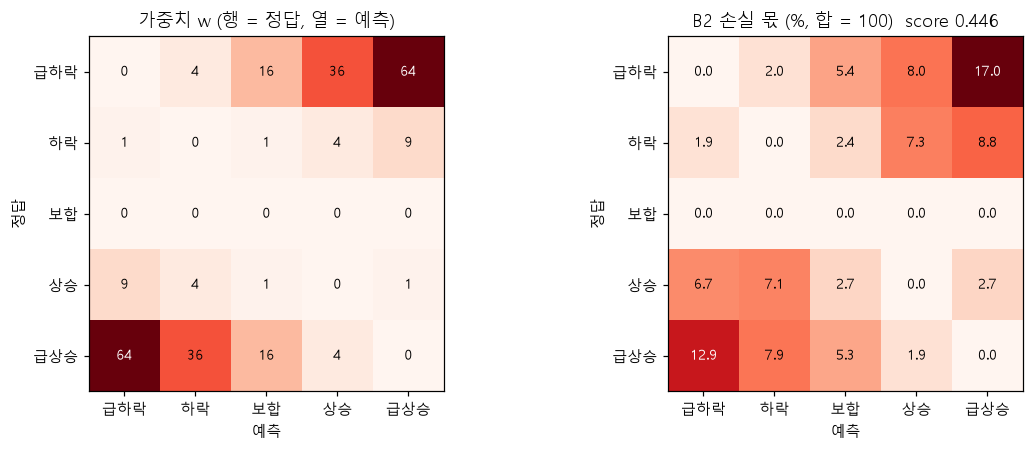

정답 등급별 손실 몫: {'급하락': np.float64(32.4), '하락': np.float64(20.4), '보합': np.float64(0.0), '상승': np.float64(19.2), '급상승': np.float64(28.1)}
정답 등급 비율     : {'급하락': np.float64(6.5), '하락': np.float64(24.2), '보합': np.float64(35.0), '상승': np.float64(27.0), '급상승': np.float64(7.4)}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
U.plot_heatmap(ax[0], pd.DataFrame(WEIGHT, index=LAB, columns=LAB), "가중치 w (행 = 정답, 열 = 예측)", cmap="Reds")
b2 = pred[pred.candidate == "B2"]
A = anatomy(b2["label"], b2["pred"])
U.plot_heatmap(ax[1], pd.DataFrame(A["loss"] / A["loss"].sum() * 100, index=LAB, columns=LAB),
               f"B2 손실 몫 (%, 합 = 100)  score {A['score']:.3f}", fmt="{:.1f}", cmap="Reds")
plt.tight_layout(); plt.show()
share = A["loss"].sum(1) / A["loss"].sum()
print("정답 등급별 손실 몫:", dict(zip(LAB, (share * 100).round(1))))
print("정답 등급 비율     :", dict(zip(LAB, (A['O'].sum(1) / A['O'].sum() * 100).round(1))))

### 1-2. 점수 = 1 − 분자 / 분모 : 과감할수록 분모가 커짐

**선 그래프(line plot)** 는 x 가 변할 때 y 가 어떻게 변하는지를 이어서 보여 줌. 여기서 x = 갭 배율 k.

- **분자** `Σ w·O / N` : 실제 벌점 (k 를 키우면 극단 예측이 늘어 벌점도 커짐)
- **분모** `Σ w·E / N` : "예측 분포를 그대로 두고 무작위로 찍었을 때"의 벌점. 예측이 양 끝으로 퍼질수록 커짐
- score 는 둘의 비율이라, 분모가 분자보다 빨리 커지는 동안은 **과감하게 찍을수록 점수가 오름**.
  B2 의 k ≈ 5 는 그 균형점임

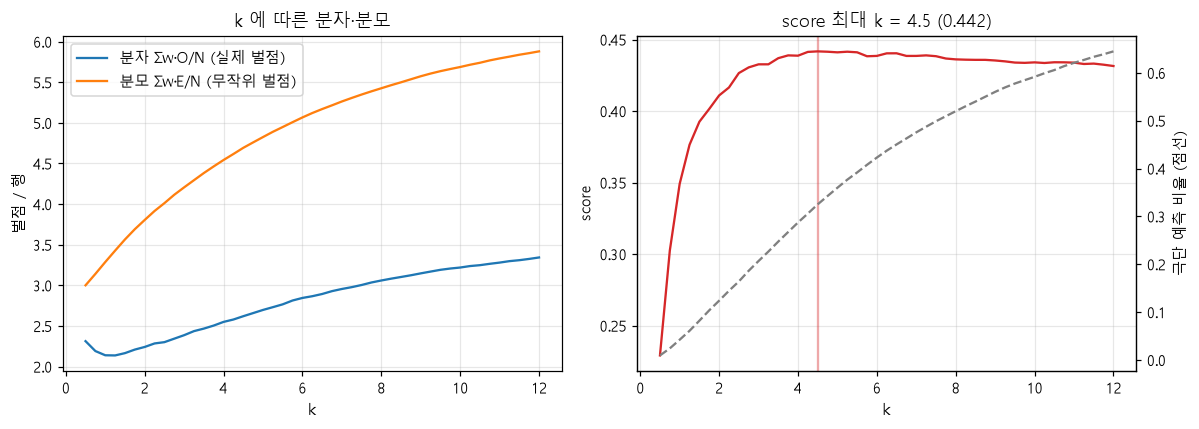

실제 극단 비율 0.145  vs  최적 k 에서 극단 예측 비율 0.325


In [5]:
ks = np.arange(0.5, 12.01, 0.25)
rows = []
for k in ks:
    a = anatomy(panel["label"], to_label(k * panel["gap_pct"].to_numpy()))
    rows.append({"k": k, "score": a["score"], "num": a["num"], "den": a["den"],
                 "pred_extreme": np.isin(to_label(k * panel["gap_pct"].to_numpy()), (0, 4)).mean()})
kk = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(kk.k, kk.num, label="분자 Σw·O/N (실제 벌점)"); ax[0].plot(kk.k, kk.den, label="분모 Σw·E/N (무작위 벌점)")
ax[0].set(xlabel="k", ylabel="벌점 / 행", title="k 에 따른 분자·분모"); ax[0].legend()
ax[1].plot(kk.k, kk.score, color="C3", label="score"); ax2 = ax[1].twinx()
ax2.plot(kk.k, kk.pred_extreme, color="gray", ls="--", label="극단 예측 비율"); ax2.grid(False)
best = kk.loc[kk.score.idxmax()]
ax[1].axvline(best.k, color="C3", alpha=.4); ax[1].set(xlabel="k", ylabel="score", title=f"score 최대 k = {best.k} ({best.score:.3f})")
ax2.set_ylabel("극단 예측 비율 (점선)")
plt.tight_layout(); plt.show()
print(f"실제 극단 비율 {np.isin(panel.label, (0, 4)).mean():.3f}  vs  최적 k 에서 극단 예측 비율 {best.pred_extreme:.3f}")

## 2. Oracle 사다리 — 무엇을 더 알면 점수가 오르는가

정답의 일부를 "몰래" 알려 주고 점수가 얼마나 오르는지 보면, **어떤 정보가 병목인지** 알 수 있음.
모든 단계는 같은 방식(학습 fold 에서 k 선택 → 평가 fold 점수)으로 계산함.

| 단계 | 신호 s | 의미 |
|---|---|---|
| FLAT | 0 | 전부 보합 |
| 방향만 무작위 | ±\|갭\| (부호 무작위) | 크기 정보만 있을 때 |
| **B2** | 갭 | 현재 모델 (08:00 프리마켓) |
| 09:30 시가 갭 | 시가/전일 종가 − 1 | 1시간 30분 더 늦은 정보 (규칙 위반, 상한 참고) |
| 방향 oracle | sign(r) · \|갭\| | 크기는 갭, **방향만 정답** |
| 크기 oracle | sign(갭) · \|r\| | 방향은 갭, **크기만 정답** |
| 완전 oracle | r | 1.0 |

**막대 그래프(bar chart)** 는 범주별 값을 막대 길이로 비교하는 그림임.

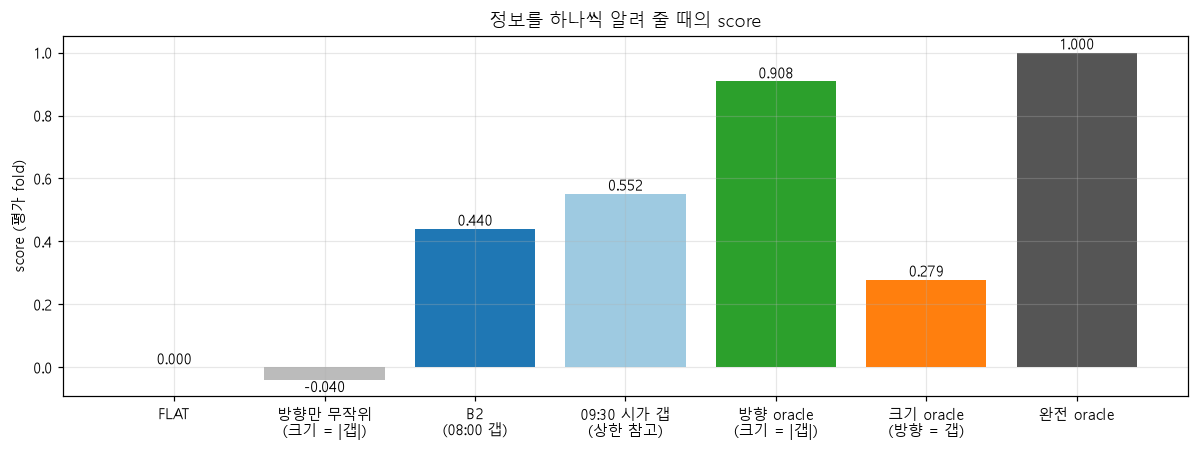

In [6]:
rng = np.random.default_rng(0)
r, g = panel["ret_pct"].to_numpy(), panel["gap_pct"].to_numpy()
rand_sign = rng.choice([-1, 1], len(panel))
ladder = {
    "FLAT": (lambda d: np.zeros(len(d)), 1.0),
    "방향만 무작위\n(크기 = |갭|)": (lambda d: rand_sign * np.abs(g), None),
    "B2\n(08:00 갭)": (lambda d: g, None),
    "09:30 시가 갭\n(상한 참고)": (lambda d: d["open_gap"].to_numpy(), None),
    "방향 oracle\n(크기 = |갭|)": (lambda d: np.sign(r) * np.abs(g), None),
    "크기 oracle\n(방향 = 갭)": (lambda d: np.sign(g) * np.abs(r), 1.0),
    "완전 oracle": (lambda d: r, 1.0),
}
res = {name: fold_score(panel, f, k)[0] for name, (f, k) in ladder.items()}
fig, ax = plt.subplots(figsize=(11, 4.2))
cols = ["#bbb", "#bbb", "C0", "#9ecae1", "C2", "C1", "#555"]
bars = ax.bar(list(res), list(res.values()), color=cols)
ax.bar_label(bars, fmt="%.3f"); ax.set(ylabel="score (평가 fold)", title="정보를 하나씩 알려 줄 때의 score")
plt.tight_layout(); plt.show()

### 2-1. 방향 적중률이 오르면 점수가 얼마나 오르나

방향 oracle 을 **일부 행에만** 적용해 "갭 방향 적중률"을 조금씩 올려 봄. x = 방향 적중률, y = score.
**산점도+선(scatter + line)** 으로 둘의 관계(기울기)를 봄.

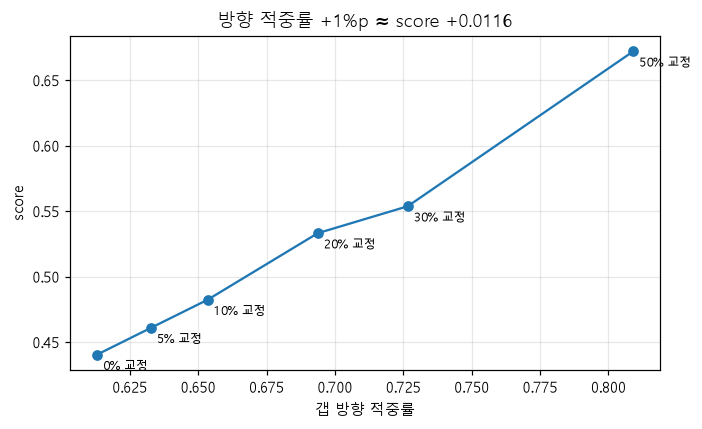

현재 갭 방향 적중률 0.613


In [7]:
base_hit = (np.sign(r) == np.sign(g))[np.abs(g) > 0].mean()
rows = []
for frac in [0, .05, .1, .2, .3, .5]:
    fix = rng.random(len(panel)) < frac
    s = np.where(fix, np.sign(r) * np.abs(g), g)
    hit = (np.sign(r) == np.sign(s))[np.abs(s) > 0].mean()
    rows.append({"frac": frac, "hit": hit, "score": fold_score(panel, lambda d, s=s: s)[0]})
hh = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(hh.hit, hh.score, "o-")
for _, t in hh.iterrows():
    ax.annotate(f"{int(t.frac*100)}% 교정", (t.hit, t.score), textcoords="offset points", xytext=(4, -10), fontsize=8)
slope = np.polyfit(hh.hit, hh.score, 1)[0]
ax.set(xlabel="갭 방향 적중률", ylabel="score", title=f"방향 적중률 +1%p ≈ score +{slope/100:.4f}")
plt.tight_layout(); plt.show()
print(f"현재 갭 방향 적중률 {base_hit:.3f}")

## 3. 프리마켓 갭이 설명하는 범위

### 3-1. 갭 vs 당일 등락률

**hexbin** 은 점이 너무 많을 때 평면을 육각형 칸으로 나눠 칸마다 점 개수를 색으로 표시하는 산점도임.
점선 = 등급 경계(±0.6, ±2.5%). 대각선(y = x)에서 위아래로 퍼진 정도가 **08:00 이후 움직임(rest)** 이고, 이것은 cutoff 이후라 원리적으로 알 수 없음.

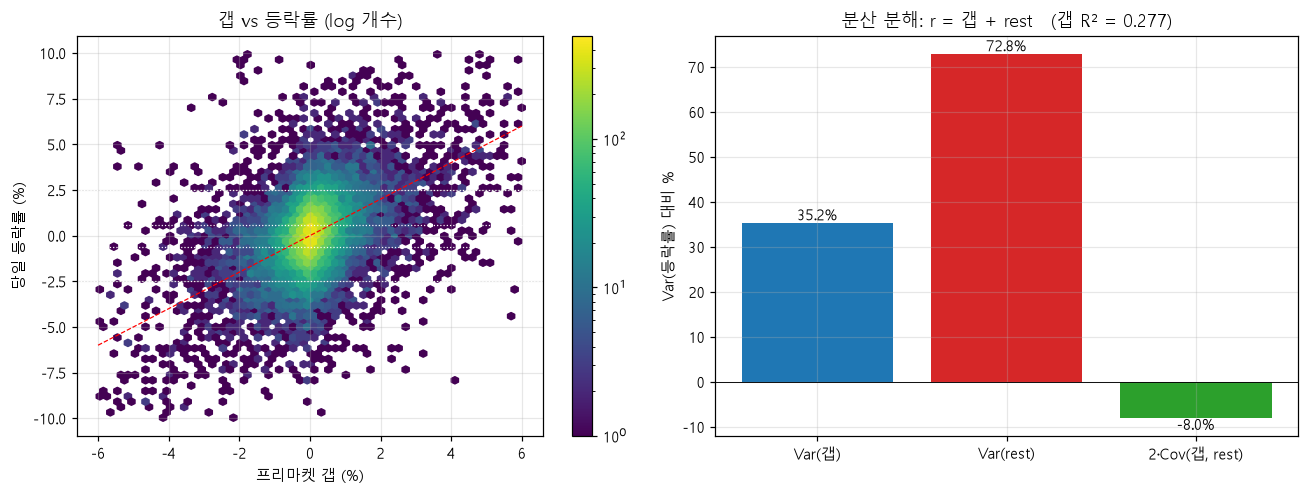

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
m = (np.abs(g) < 6) & (np.abs(r) < 10)
hb = ax[0].hexbin(g[m], r[m], gridsize=60, bins="log", cmap="viridis")
for c in CUTS:
    ax[0].axhline(c, color="w", ls=":", lw=.8)
ax[0].plot([-6, 6], [-6, 6], "r--", lw=.8)
ax[0].set(xlabel="프리마켓 갭 (%)", ylabel="당일 등락률 (%)", title="갭 vs 등락률 (log 개수)")
plt.colorbar(hb, ax=ax[0])

# 분산 분해: r = gap + rest
v = pd.Series({"Var(갭)": np.var(g), "Var(rest)": np.var(panel.rest), "2·Cov(갭, rest)": 2 * np.cov(g, panel.rest)[0, 1]})
R2 = np.corrcoef(g, r)[0, 1] ** 2
bars = ax[1].bar(v.index, v.values / np.var(r) * 100, color=["C0", "C3", "C2"])
ax[1].bar_label(bars, fmt="%.1f%%"); ax[1].axhline(0, color="k", lw=.6)
ax[1].set(ylabel="Var(등락률) 대비 %", title=f"분산 분해: r = 갭 + rest   (갭 R² = {R2:.3f})")
plt.tight_layout(); plt.show()

### 3-2. 갭 크기별 방향 적중률과 갭 분포

왼쪽 축: **갭 크기 구간별 방향 적중률** (sign(r) = sign(갭) 비율). 오른쪽 막대: 그 구간에 속한 행 비율.
갭이 작은 행이 대부분이고, 그 구간에서 적중률은 동전 던지기에 가까움 → 여기서 점수를 잃음.

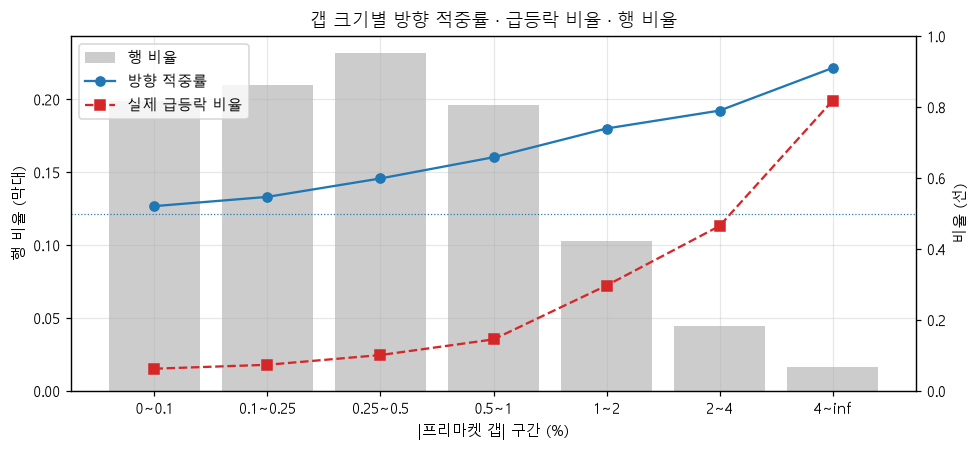

,hit,ext,n,share
bin,,,,
"[0.0, 0.1)",0.5210,0.0630,4454,0.1990
"[0.1, 0.25)",0.5470,0.0740,4696,0.2100
"[0.25, 0.5)",0.5990,0.1010,5191,0.2320
"[0.5, 1.0)",0.6590,0.1450,4386,0.1960
"[1.0, 2.0)",0.7400,0.2970,2309,0.1030
"[2.0, 4.0)",0.7900,0.4650,996,0.0440
"[4.0, inf)",0.9100,0.8180,368,0.0160


In [9]:
t = panel.assign(ag=np.abs(g), hit=(np.sign(r) == np.sign(g)).astype(float), ext=np.isin(panel.label, (0, 4)).astype(float))
edges = [0, .1, .25, .5, 1, 2, 4, np.inf]
t["bin"] = pd.cut(t.ag, edges, right=False)
gb = t.groupby("bin", observed=True).agg(hit=("hit", "mean"), ext=("ext", "mean"), n=("hit", "size"))
gb["share"] = gb.n / gb.n.sum()
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(gb)); lab = [f"{a.left:g}~{a.right:g}" for a in gb.index]
ax.bar(x, gb.share, color="#ccc", label="행 비율"); ax.set_ylabel("행 비율 (막대)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(x, gb.hit, "o-", color="C0", label="방향 적중률"); ax2.plot(x, gb.ext, "s--", color="C3", label="실제 급등락 비율")
ax2.axhline(.5, color="C0", ls=":", lw=.8); ax2.set_ylim(0, 1); ax2.set_ylabel("비율 (선)")
ax.set_xticks(x, lab); ax.set_xlabel("|프리마켓 갭| 구간 (%)"); ax.set_title("갭 크기별 방향 적중률 · 급등락 비율 · 행 비율")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax2.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
gb.round(3)

### 3-3. 되돌림: 갭 이후 평균적으로 얼마나 더 가는가

**구간 평균 그래프(binned plot)** 는 x 를 분위 구간으로 나눠 구간마다 y 의 평균을 찍은 그림임. 점이 많아도 평균 관계가 보임.
기울기가 1 보다 작으면 갭의 일부가 장중에 되돌아간다는 뜻 (EDA·누수 감사의 rest 검정 ρ = −0.067 과 같은 현상).

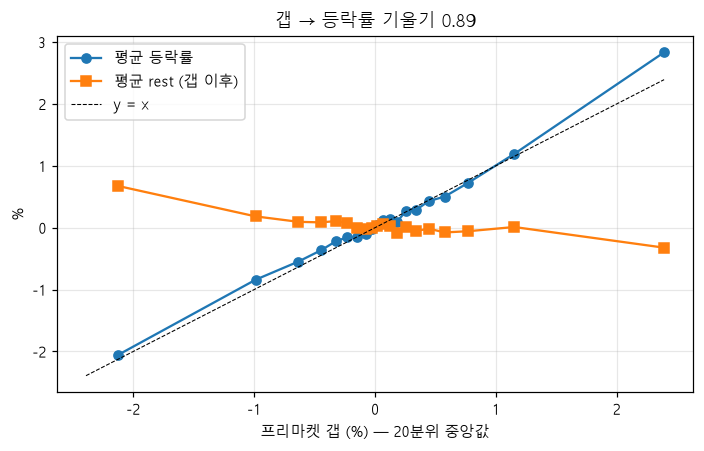

In [10]:
bb = U.binned(panel.assign(r=r), "gap_pct", ["r", "rest"], q=20)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(bb.x_mid, bb.r, "o-", label="평균 등락률"); ax.plot(bb.x_mid, bb.rest, "s-", label="평균 rest (갭 이후)")
lim = np.abs(bb.x_mid).max(); ax.plot([-lim, lim], [-lim, lim], "k--", lw=.7, label="y = x")
slope = np.polyfit(g, r, 1)[0]
ax.set(xlabel="프리마켓 갭 (%) — 20분위 중앙값", ylabel="%", title=f"갭 → 등락률 기울기 {slope:.2f}"); ax.legend()
plt.tight_layout(); plt.show()

## 4. 갭 말고 다른 feature 는 무엇을 알려 주는가

같은 갭이면서 feature 만 다를 때 결과가 달라지는지를 **부분 순위상관(partial Spearman ρ)** 으로 봄.
- **크기 정보**: ρ(|r|, f | |갭|) — 같은 |갭| 에서 f 가 크면 더 크게 움직이는가
- **방향 정보**: ρ(r, f | 갭) — 같은 갭에서 f 가 크면 더 오르는가

**가로 막대 그래프** 로 두 값을 나란히 놓음. 표본이 2만 행이라 |ρ| ≈ 0.014 가 대략 유의 기준(2σ)임.

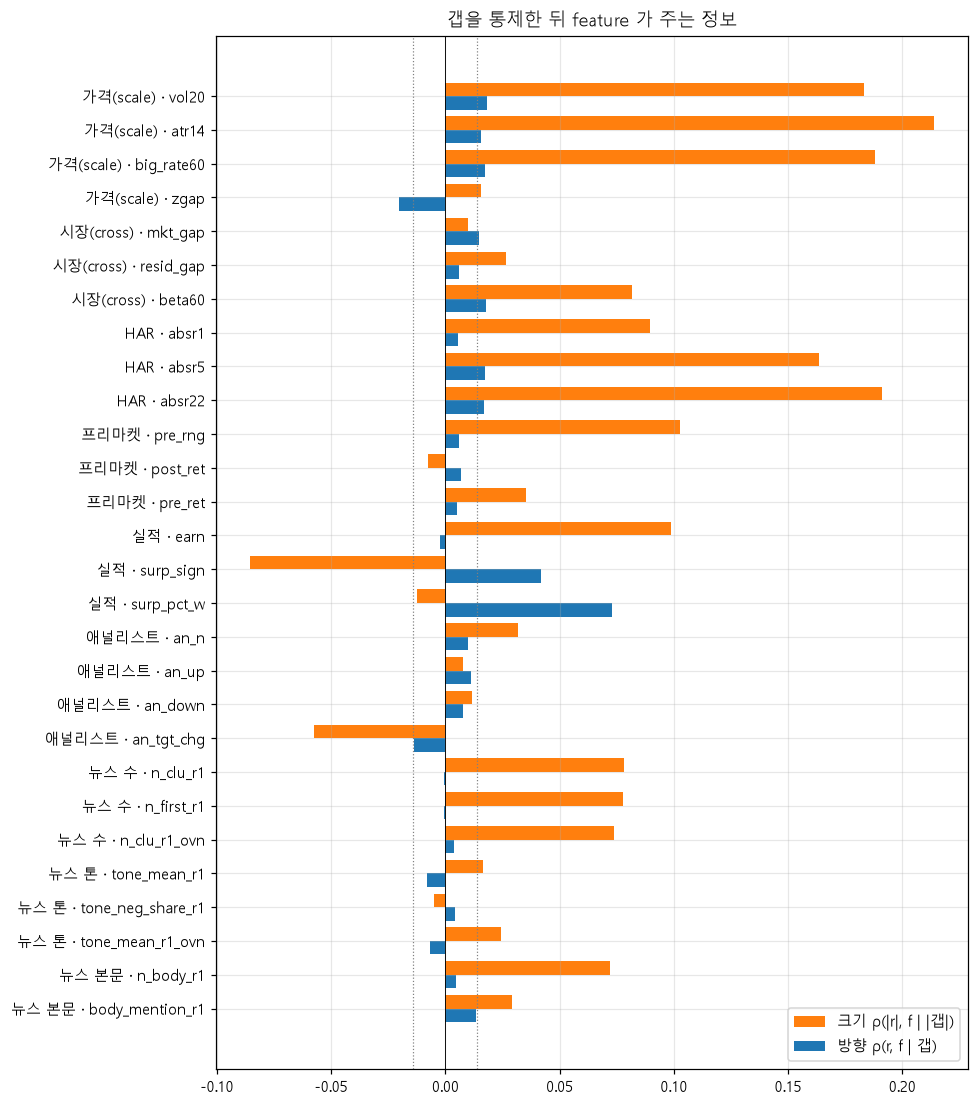

평균 |크기 ρ| = 0.071,  평균 |방향 ρ| = 0.013


In [11]:
# -----------------------------------------------------------------------------
# 역할  : 통제 변수 c 를 뺀 부분 순위상관
# 수식  : ρ( rank(y) − 선형(rank(c)),  rank(f) − 선형(rank(c)) )
# Input : y, f, c  Series
# Output: (ρ, n)
# -----------------------------------------------------------------------------
def partial_rho(y, f, c):
    m = y.notna() & f.notna() & c.notna()
    if m.sum() < 300 or f[m].nunique() < 2:
        return np.nan, int(m.sum())
    res = lambda a: a.rank() - np.polyval(np.polyfit(c[m].rank(), a.rank(), 1), c[m].rank())
    return float(np.corrcoef(res(y[m]), res(f[m]))[0, 1]), int(m.sum())

FEATS = {"가격(scale)": ["vol20", "atr14", "big_rate60", "zgap"], "시장(cross)": ["mkt_gap", "resid_gap", "beta60"],
         "HAR": ["absr1", "absr5", "absr22"], "프리마켓": ["pre_rng", "post_ret", "pre_ret"],
         "실적": ["earn", "surp_sign", "surp_pct_w"], "애널리스트": ["an_n", "an_up", "an_down", "an_tgt_chg"],
         "뉴스 수": ["n_clu_r1", "n_first_r1", "n_clu_r1_ovn"], "뉴스 톤": ["tone_mean_r1", "tone_neg_share_r1", "tone_mean_r1_ovn"],
         "뉴스 본문": ["n_body_r1", "body_mention_r1"]}
rows = []
R, Gs = panel["ret_pct"], panel["gap_pct"]
for grp, cols in FEATS.items():
    for c in cols:
        if c not in panel:
            continue
        mag, n = partial_rho(R.abs(), panel[c], Gs.abs())
        dirn, _ = partial_rho(R, panel[c], Gs)
        rows.append({"group": grp, "feature": c, "크기 ρ": mag, "방향 ρ": dirn, "n": n})
pr = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 0.32 * len(pr) + 1.2))
y = np.arange(len(pr))[::-1]
ax.barh(y + .2, pr["크기 ρ"], height=.4, color="C1", label="크기 ρ(|r|, f | |갭|)")
ax.barh(y - .2, pr["방향 ρ"], height=.4, color="C0", label="방향 ρ(r, f | 갭)")
ax.set_yticks(y, pr.group + " · " + pr.feature)
for v in (-.014, .014):
    ax.axvline(v, color="gray", ls=":", lw=.8)
ax.axvline(0, color="k", lw=.6); ax.legend(loc="lower right"); ax.set_title("갭을 통제한 뒤 feature 가 주는 정보")
plt.tight_layout(); plt.show()
print("평균 |크기 ρ| = %.3f,  평균 |방향 ρ| = %.3f" % (pr["크기 ρ"].abs().mean(), pr["방향 ρ"].abs().mean()))

### 4-1. 크기 정보가 점수로 안 바뀌는 이유

크기 정보로 "크게 움직일 종목"을 골라 k 를 키우면, 같은 종목에서 **반대 방향 극단(가중치 64)** 오답도 같이 늘어남.
아래 표는 B2 가 극단을 예측한 행을, 예측된 크기(HAR) 삼분위로 나눠 결과를 본 것임.
**누적 막대(stacked bar)** 는 한 막대 안을 결과 비율로 나눠 칠한 그림임.

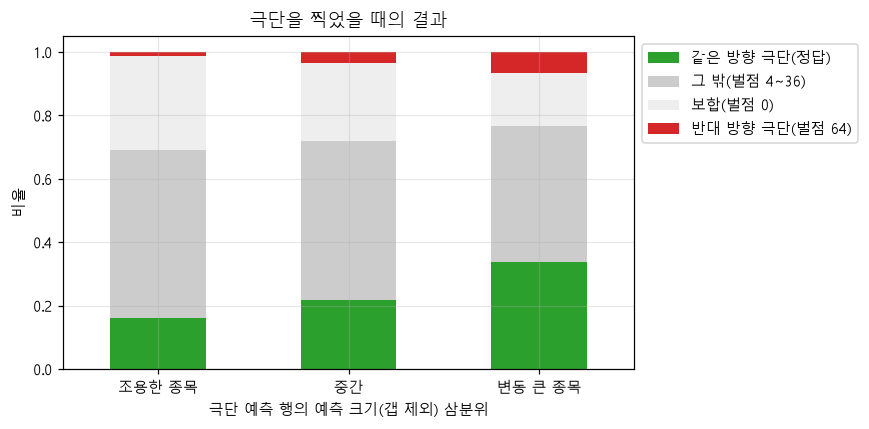

결과,같은 방향 극단(정답),그 밖(벌점 4~36),보합(벌점 0),반대 방향 극단(벌점 64)
tier,,,,
조용한 종목,0.1600,0.5300,0.2970,0.0130
중간,0.2170,0.5010,0.2470,0.0350
변동 큰 종목,0.3360,0.4300,0.1690,0.0650


In [12]:
t = panel.copy()
k_b2 = fit_k(t.gap_pct.to_numpy(), t.label.to_numpy())
t["p"] = to_label(k_b2 * t.gap_pct.to_numpy())
X = np.log1p(t[["abs_gap", "absr5", "absr22"]].clip(lower=0).fillna(0)).to_numpy()
coef = np.linalg.lstsq(np.c_[np.ones(len(X)), X], np.log(np.minimum(t.ret_pct.abs(), 15) + .1), rcond=None)[0]
t["mag_excess"] = X[:, 1:] @ coef[2:]            # |갭| 기여를 뺀 예측 크기 (M2 의 excess)
e = t[np.isin(t.p, (0, 4))].copy()
e["tier"] = pd.qcut(e.mag_excess, 3, labels=["조용한 종목", "중간", "변동 큰 종목"])
same = np.where(e.p == 0, e.label == 0, e.label == 4)
opp = np.where(e.p == 0, e.label == 4, e.label == 0)
e["결과"] = np.select([same, opp, e.label == 2], ["같은 방향 극단(정답)", "반대 방향 극단(벌점 64)", "보합(벌점 0)"], "그 밖(벌점 4~36)")
ct = pd.crosstab(e.tier, e["결과"], normalize="index")[["같은 방향 극단(정답)", "그 밖(벌점 4~36)", "보합(벌점 0)", "반대 방향 극단(벌점 64)"]]
ax = ct.plot(kind="bar", stacked=True, figsize=(8, 4), color=["C2", "#ccc", "#eee", "C3"], rot=0)
ax.set(ylabel="비율", xlabel="극단 예측 행의 예측 크기(갭 제외) 삼분위", title="극단을 찍었을 때의 결과")
ax.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
ct.round(3)

## 5. 관측된 개선은 평가 잡음보다 큰가

### 5-1. 시간별 B2 점수

월별 표본 밖 score 를 **선 그래프** 로 봄. 음영 = 3개 추첨 사이 범위. 시기마다 점수가 크게 출렁이면
몇 달짜리 평가 구간의 점수 차이는 그 출렁임에 묻힘.

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_26524\2544804833.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax.plot(xm, mon.mean(1), "o-"); ax.fill_between(xm, mon.min(1), mon.max(1), alpha=.25)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_26524\2544804833.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  ax.plot(xm, mon.mean(1), "o-"); ax.fill_between(xm, mon.min(1), mon.max(1), alpha=.25)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_26524\2544804833.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  ax.plot(xm, mon.mean(1), "o-"); ax.fill_between(xm, mon.min(1), mon.max(1), alpha=.25)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_26524\2544804833.py:7: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax.set(ylabel="score", title=f"월별 B2 score (표

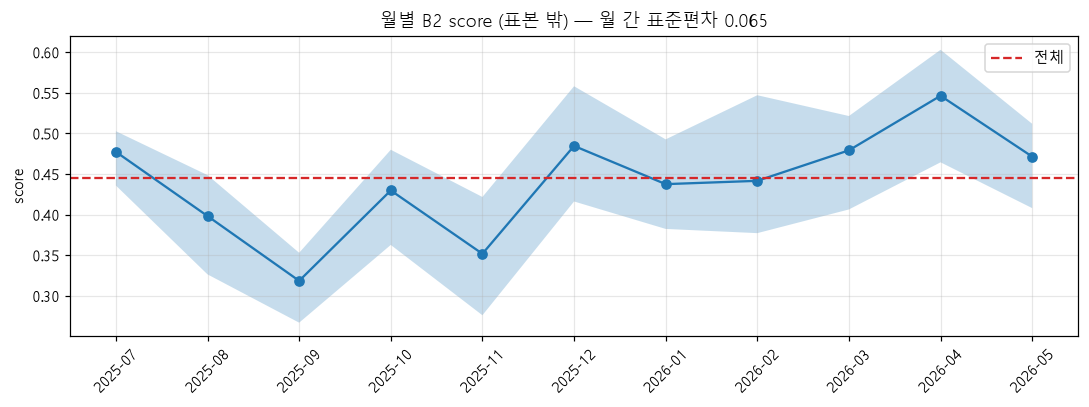

In [13]:
b2 = pred[pred.candidate == "B2"].assign(month=lambda d: pd.to_datetime(d.target).dt.to_period("M"))
mon = b2.groupby(["month", "draw"]).apply(lambda d: fast_score(d.label, d.pred), include_groups=False).unstack()
fig, ax = plt.subplots(figsize=(10, 3.8))
xm = mon.index.astype(str)
ax.plot(xm, mon.mean(1), "o-"); ax.fill_between(xm, mon.min(1), mon.max(1), alpha=.25)
ax.axhline(fast_score(b2.label, b2.pred), color="C3", ls="--", label="전체")
ax.set(ylabel="score", title=f"월별 B2 score (표본 밖) — 월 간 표준편차 {mon.mean(1).std():.3f}"); ax.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 5-2. 종목별 점수

종목마다 B2 score 를 **막대** 로 그림 (색 = 학습에 있던 종목 / 처음 보는 종목).
채점은 10개 처음 보는 종목을 포함하므로, 어떤 종목이 뽑히느냐가 점수에 직접 영향을 줌.

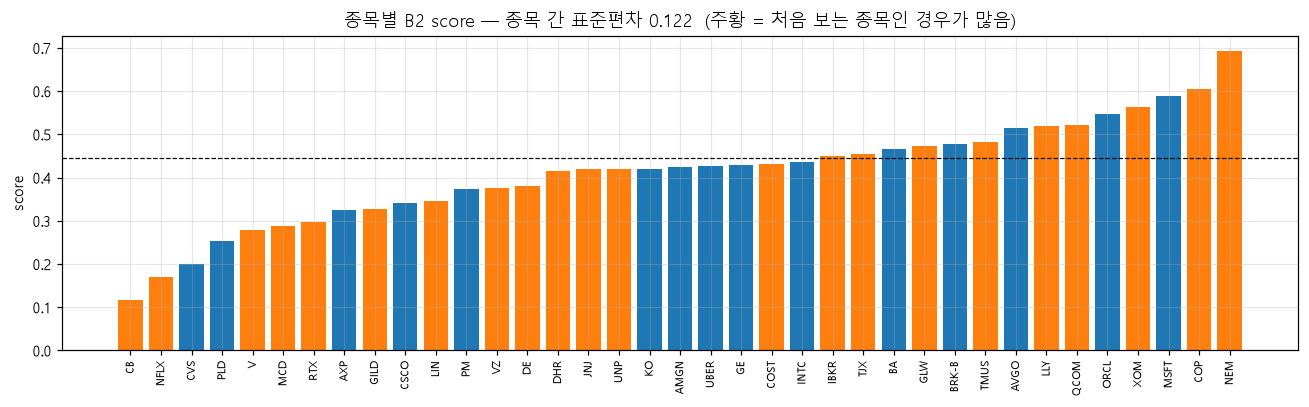

In [14]:
sym = b2.groupby("symbol").apply(lambda d: pd.Series({"score": fast_score(d.label, d.pred), "seen": d.seen.mean() > .5,
                                                        "n": len(d)}), include_groups=False).sort_values("score")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(sym.index, sym.score, color=np.where(sym.seen, "C0", "C1"))
ax.axhline(fast_score(b2.label, b2.pred), color="k", ls="--", lw=.8)
ax.set(ylabel="score", title=f"종목별 B2 score — 종목 간 표준편차 {sym.score.std():.3f}  (주황 = 처음 보는 종목인 경우가 많음)")
plt.xticks(rotation=90, fontsize=7); plt.tight_layout(); plt.show()

### 5-3. 추첨·fold 마다 개선 폭은 얼마나 흔들리나

M2 의 최고 후보 H4(HAR + 프리마켓 excess) − B2 를 **추첨 3 × fold 3 = 9 칸** 으로 나눠 봄 (heatmap).
같은 후보라도 칸마다 Δ 가 달라지는 폭 = 평가 잡음의 크기.

또 **같은 설정(제목 TF-IDF 분류기)** 을 추첨(seed)만 바꿔 두 번 돌린 결과(T5 vs M4)를 나란히 둠.

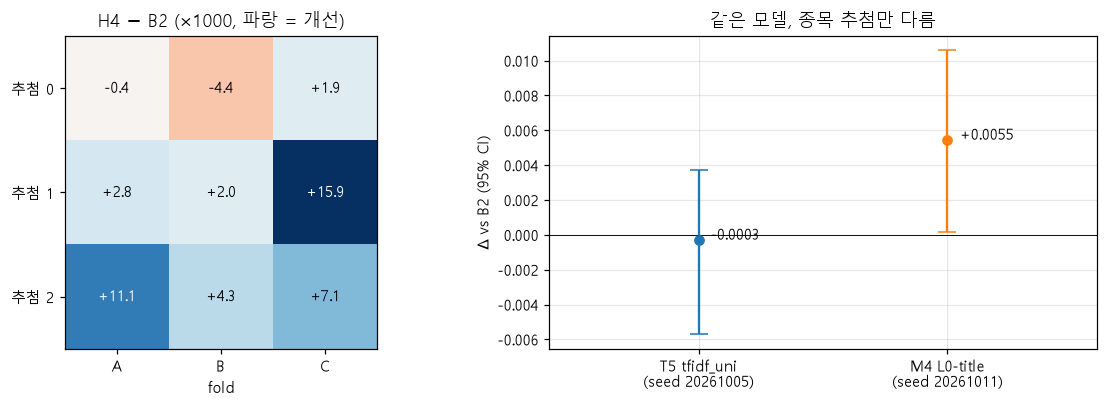

9칸 Δ: 평균 +0.0045, 표준편차 0.0061, 최소 -0.0044, 최대 +0.0159


In [15]:
h4 = pred[pred.candidate == "H4-har+pre-excess"] if "H4-har+pre-excess" in set(pred.candidate) else None
cell = {}
for (dr, fd), d in pred[pred.candidate == "B2"].groupby(["draw", "fold"]):
    o = h4[(h4.draw == dr) & (h4.fold == fd)]
    cell[(dr, fd)] = fast_score(o.label, o.pred) - fast_score(d.label, d.pred)
cm = pd.Series(cell).unstack()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
v = cm.to_numpy() * 1000; lim = np.abs(v).max()
ax[0].imshow(v, cmap="RdBu", vmin=-lim, vmax=lim)                     # 0 = 흰색, 파랑 = H4 가 좋음
for (i, j), val in np.ndenumerate(v):
    ax[0].text(j, i, f"{val:+.1f}", ha="center", va="center", fontsize=10, color="white" if abs(val) > .6 * lim else "black")
ax[0].set_xticks(range(v.shape[1]), cm.columns); ax[0].set_yticks(range(v.shape[0]), [f"추첨 {i}" for i in cm.index])
ax[0].set(title="H4 − B2 (×1000, 파랑 = 개선)", xlabel="fold"); ax[0].grid(False)
seed = pd.Series({"T5 tfidf_uni\n(seed 20261005)": None, "M4 L0-title\n(seed 20261011)": None})
for run, cand, key in [("t5_vectorizer_*", "tfidf_uni", seed.index[0]), ("m4_body_*", "L0-title", seed.index[1])]:
    cc = pd.read_csv(sorted(glob.glob(str(ROOT / "runs" / run / "compare.csv")))[-1])
    seed[key] = cc.set_index("candidate").loc[cand, ["delta", "ci_low", "ci_high"]].to_numpy(float)
for i, (k_, (dlt, lo, hi)) in enumerate(seed.items()):
    ax[1].errorbar(i, dlt, yerr=[[dlt - lo], [hi - dlt]], fmt="o", capsize=6, color=f"C{i}")
    ax[1].annotate(f"{dlt:+.4f}", (i, dlt), xytext=(8, 0), textcoords="offset points")
ax[1].axhline(0, color="k", lw=.6); ax[1].set_xticks([0, 1], seed.index); ax[1].set_xlim(-.6, 1.6)
ax[1].set(ylabel="Δ vs B2 (95% CI)", title="같은 모델, 종목 추첨만 다름")
plt.tight_layout(); plt.show()
print(f"9칸 Δ: 평균 {cm.values.mean():+.4f}, 표준편차 {cm.values.std(ddof=1):.4f}, 최소 {cm.values.min():+.4f}, 최대 {cm.values.max():+.4f}")

### 5-4. 지금까지 모든 후보의 ΔScore

**forest plot** 은 여러 비교 결과를 한 줄씩 점(추정치)과 가로선(신뢰구간)으로 늘어놓은 그림임. 0 의 오른쪽이면 B2 보다 좋음.
회색 띠 = 5-3 에서 본 추첨 잡음 크기(±0.006). DEV 실험만 (E6 lockbox 제외).

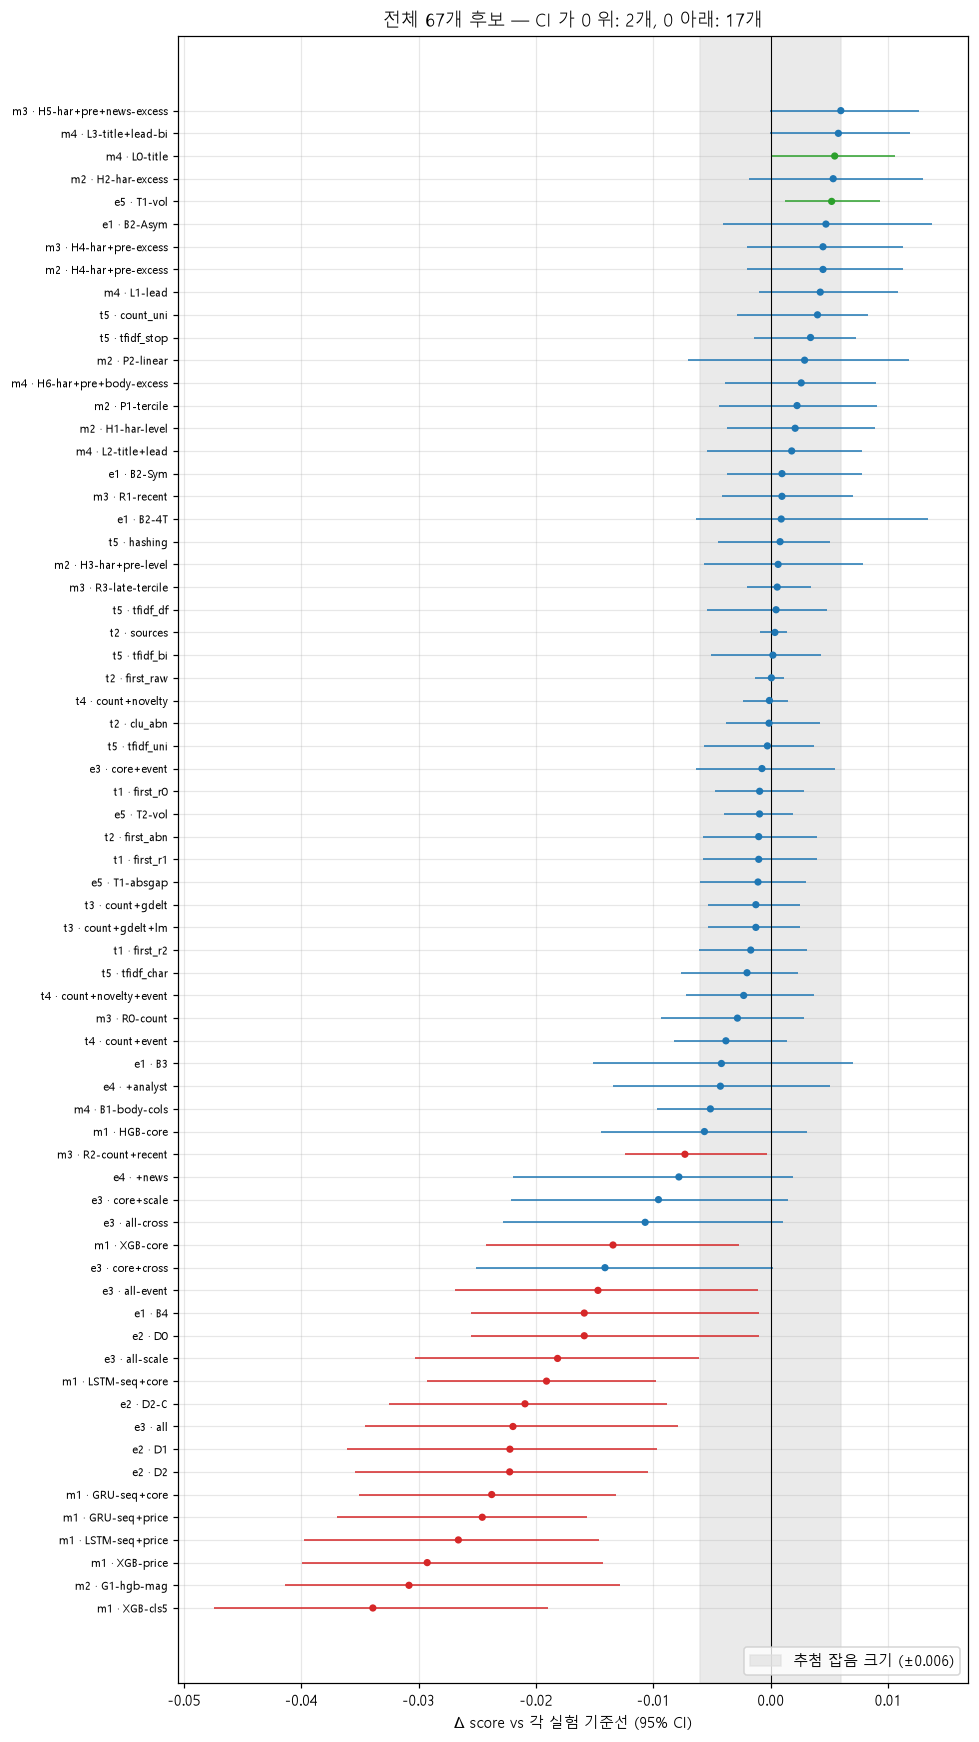

In [16]:
rows = []
for f in glob.glob(str(ROOT / "runs" / "*" / "compare.csv")):
    run = Path(f).parent.name
    if run.startswith(("e6_", "analyze", "audit")) or "explain" in run:
        continue
    cfg = run.rsplit("_", 2)[0]
    rows.append(pd.read_csv(f).assign(config=cfg, run=run, mtime=Path(f).stat().st_mtime))
allc = pd.concat(rows)
allc = allc[~((allc.delta == 0) & (allc.ci_low == 0) & (allc.ci_high == 0))]       # 입력이 없어 평가되지 않은 후보 (LM·FinBERT 미배치)
allc = allc[allc.mtime == allc.groupby("config").mtime.transform("max")]          # config 마다 최신 실행
allc = allc[allc.delta > -0.06].sort_values("delta")                                 # 크게 진 후보는 축 밖 (표로 확인)
fig, ax = plt.subplots(figsize=(9, 0.22 * len(allc) + 1.2))
y = np.arange(len(allc))
ax.axvspan(-.006, .006, color="#ddd", alpha=.6, label="추첨 잡음 크기 (±0.006)")
col = np.where(allc.ci_low > 0, "C2", np.where(allc.ci_high < 0, "C3", "C0"))
ax.errorbar(allc.delta, y, xerr=[allc.delta - allc.ci_low, allc.ci_high - allc.delta], fmt="none", ecolor=col, lw=1)
ax.scatter(allc.delta, y, c=col, s=14, zorder=3)
ax.set_yticks(y, allc.config.str.split("_").str[0] + " · " + allc.candidate, fontsize=7)
ax.axvline(0, color="k", lw=.7); ax.set_xlabel("Δ score vs 각 실험 기준선 (95% CI)"); ax.legend(loc="lower right")
ax.set_title(f"전체 {len(allc)}개 후보 — CI 가 0 위: {(allc.ci_low > 0).sum()}개, 0 아래: {(allc.ci_high < 0).sum()}개")
plt.tight_layout(); plt.show()

## 6. 결론 — 성능이 안 나오는 원인

(아래 숫자는 위 셀 실행 결과에서 옮김)

**한 줄 요약: 점수의 병목은 "방향"인데, 09:30 전에 쓸 수 있는 정보 중 방향을 알려 주는 것은 프리마켓 갭 하나뿐이고, 갭은 당일 움직임의 28% 만 설명함.
나머지 feature 는 크기만 알려 주는데, 이 점수에서 크기 정보는 방향 정보 없이는 점수로 바뀌지 않음. 그리고 남은 개선 여지(+0.005)는 평가 잡음(±0.006)과 구분되지 않음.**

### 원인 1. 점수 구조: 손실의 60% 가 전체의 14% 인 급등락 날에서 나옴 (1절)
- 가중치 `(i − 2)²` 때문에 **정답이 보합인 날(35%)은 무엇을 찍어도 벌점 0**. 손실은 정답이 급하락·급상승인 날(합 14%)에서 60.5%, 그중 **반대 극단으로 틀린 두 칸에서만 30%** (17.0% + 12.9%)
- 분모(무작위 벌점)가 예측을 양 끝으로 퍼뜨릴수록 커져서, 최적 k 에서 극단 예측 비율이 32.5% 로 실제(14.5%)의 2배가 넘음. 즉 점수는 **극단을 많이 찍되 방향은 틀리지 않는 것**을 요구함

### 원인 2. 병목은 크기가 아니라 방향 (2절)
| 알려 준 정보 | score |
|---|---|
| 방향만 무작위 (크기 = \|갭\|) | −0.040 |
| **B2 (08:00 갭)** | **0.440** |
| 09:30 시가 갭 (규칙 위반, 참고) | 0.552 |
| 크기만 정답 (방향 = 갭) | 0.279 |
| **방향만 정답 (크기 = \|갭\|)** | **0.908** |
- 크기를 완벽히 알아도 0.28 로 **B2 보다 낮고**, 방향만 알면 0.91. 크기 정보는 방향이 틀린 극단을 늘려 오히려 해로울 수 있음
- 갭 방향 적중률 +1%p ≈ score +0.012. 지금 적중률 61.3%
- 시가(09:30)만 알아도 +0.11 → 08:00~09:30 사이에 정보가 많이 들어오지만, 이는 cutoff 규칙상 쓸 수 없음

### 원인 3. 갭은 방향을 큰 갭에서만 알려 줌 (3절)
- 갭 R² = 0.277. 당일 분산의 **73% 가 08:00 이후 움직임(rest)** 이고, 갭과 rest 는 음의 공분산(−8%, 되돌림)
- **행의 64% 는 \|갭\| < 0.5%** 이고 그 구간 방향 적중률은 52~60% (동전 던지기 수준). \|갭\| ≥ 2% 는 6% 뿐이지만 적중률 79~91%
- 갭 → 등락률 기울기 0.89 (큰 갭은 일부 되돌아감). 관계가 거의 직선이라 학습 모델이 더할 비선형 구조가 없음 → XGBoost·LSTM·GRU 가 갭 규칙에 짐 (M1)

### 원인 4. 다른 feature 는 크기만 알려 줌 (4절)
- 갭을 통제한 뒤 평균 \|크기 ρ\| = 0.071, 평균 \|방향 ρ\| = 0.013 (유의 기준 0.014 근처). 변동성(atr14, absr22 ≈ 0.2), 실적일(0.10), 뉴스 수(0.08), 프리마켓 범위(0.10) 모두 크기 정보
- **유일한 예외는 실적 서프라이즈** (surp_pct_w 방향 ρ = 0.073, surp_sign 0.042): 실적 발표 후 같은 방향으로 더 가는 현상(PEAD). 하지만 실적일은 전체의 약 1.6% 라 전체 점수에 주는 영향이 작음 (E3 core+event Δ ≈ 0)
- 크기가 크다고 예측된 종목에서 극단을 찍으면 정답(같은 방향 극단)은 16% → 34% 로 늘지만 **반대 극단(벌점 64)도 1.3% → 6.5% 로 5배** 늘어남. 그래서 M2~M4 의 크기 보정 모델은 오히려 "변동 큰 종목의 배율을 줄이는" 쪽으로 학습됨

### 원인 5. 평가 잡음이 남은 개선 폭과 같은 크기 (5절)
- 월별 B2 score 표준편차 0.065, 종목별 0.122 → 3~4달 평가 구간·10개 처음 보는 종목이 바뀌면 점수가 크게 움직임
- 가장 좋은 후보 H4 − B2 는 9칸 평균 +0.0045 이지만 칸 간 표준편차 0.0061 (−0.004 ~ +0.016). 같은 제목 분류기가 추첨만 바꿔 −0.0003 → +0.0055
- 지금까지 후보 중 CI 가 0 위인 것은 2개(E5 T1-vol: lockbox 에서 재현 실패, M4 L0-title: 추첨에 따라 사라짐)뿐이고, 0 아래가 17개

### 그래서 무엇을 할 수 있나
1. **방향 정보가 새로 생기지 않는 한 큰 개선은 어려움**. 09:30 전에 방향을 알려 줄 후보는 시장 전체 선물·지수 프리마켓(데이터에 없음) 정도
   - 데이터 안에서 방향 정보가 있는 유일한 곳은 **실적일의 서프라이즈** → 실적일에만 신호를 서프라이즈 방향으로 조정하는 좁은 실험은 해 볼 만함 (표본이 작아 효과 확인은 어려움)
2. 남은 여지는 작은 갭 구간(행의 64%)의 처리와, 크기 정보로 **반대 극단 위험을 줄이는 쪽**(M2 H 계열)인데, 효과가 잡음 수준이라 확정하려면 여러 seed 검증이 필요
3. 보고서에서는 "모델이 약해서"가 아니라 "**정보 한계 + 점수 구조 + 평가 잡음**" 이 원인임을 위 그림으로 보이는 것이 설득력 있음